## Exploratory Experiments: Is That a Dog?

![is-that-a-dog-?](images\is-that-a-dog.png "notebook cover.")

**CONTENTS**

> STATEMENT: In this notebook, `auto_grad` is banned.

0. **Intro**
1. **Dataset**
2. **Forward & Backward Passing**
3. **Optimizers**
4. **Initializations**
5. **Normalizations**
6. **Hyperparameters**
7. **Training**
8. **Conclusion**

### 0) Intro

![demo](images\demo.gif "Figure 1: Visualizing CIFAR-10 model.")

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms

import numpy as np

import random
from io import BytesIO
from pathlib import Path
import math
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
%matplotlib inline

from IPython.display import Image, clear_output, display

#### 0.1) Visualization utils: Take a Look!

> You can just treat this as black boxes.

In [2]:
#
def loss_fn(theta: torch.Tensor) -> torch.Tensor:
    x, y = theta[0], theta[1]
    return x**2 + 10 * y**2

def grad_fn(theta: torch.Tensor) -> torch.Tensor:
    x, y = theta[0], theta[1]
    return torch.tensor([2 * x, 20 * y], dtype=theta.dtype)

def make_landscape(xlim=(-4, 4), ylim=(-3, 3), n=200):
    x = np.linspace(*xlim, n)
    y = np.linspace(*ylim, n)
    X, Y = np.meshgrid(x, y)
    Z = X**2 + 10 * Y**2
    return X, Y, Z

def run_optimizer(opt_name, lr, steps=80, theta0=(-3.5, -2.0)):
    param = torch.tensor(theta0, dtype=torch.float32)
    param.grad = None

    opts = {
        "SimpleGD": lambda: SimpleGD([param], lr=lr),
        "SGD": lambda: SGD([param], lr=lr, momentum=0.9),
        "RMSprop": lambda: RMSprop([param], lr=lr),
        "Adam": lambda: Adam([param], lr=lr),
    }
    if opt_name not in opts:
        raise ValueError(f"unknown optimizer: {opt_name}")
    opt = opts[opt_name]()

    path = [param.detach().clone().numpy()]
    losses = [float(loss_fn(param))]

    for _ in range(steps):
        opt.zero_grad()
        param.grad = grad_fn(param)
        opt.step()
        path.append(param.detach().clone().numpy())
        losses.append(float(loss_fn(param)))

    return np.array(path), losses

def plot_contours_subplots(
    configs,
    steps=80,
    theta0=(-3.5, -2.0),
    xlim=(-4, 4),
    ylim=(-3, 3),
    figsize=(10, 8),
):
    """
    configs: list of (name, lr), e.g.
      [("SimpleGD", 0.05), ("SGD", 0.05), ("RMSprop", 0.1), ("Adam", 0.2)]
    """
    X, Y, Z = make_landscape(xlim, ylim)
    fig, axes = plt.subplots(2, 2, figsize=figsize, sharex=True, sharey=True)
    axes = axes.ravel()

    for ax, (name, lr) in zip(axes, configs):
        path, _ = run_optimizer(name, lr=lr, steps=steps, theta0=theta0)
        cs = ax.contour(X, Y, Z, levels=30, cmap="coolwarm")
        ax.clabel(cs, inline=True, fontsize=7)
        ax.plot(path[:, 0], path[:, 1], "r-o", markersize=2, linewidth=1)
        ax.scatter(path[0, 0], path[0, 1], c="k", s=35, zorder=5, label="start")
        ax.scatter(0, 0, c="gold", marker="*", s=100, zorder=6, label="min")
        ax.set_title(f"{name}  lr={lr}")
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal")
        ax.grid(True, alpha=0.3)

    axes[0].legend(loc="upper right", fontsize=8)
    fig.supxlabel(r"$\theta_1$")
    fig.supylabel(r"$\theta_2$")
    fig.suptitle("toy model: loss contour & optimizer path", y=1.01)
    fig.tight_layout()
    return fig

def plot_surfaces_subplots(
    configs,
    steps=80,
    theta0=(-3.5, -2.0),
    xlim=(-4, 4),
    ylim=(-3, 3),
    figsize=(11, 9),
    surface_alpha=0.40,
):
    X, Y, Z = make_landscape(xlim, ylim)
    fig = plt.figure(figsize=figsize)

    for i, (name, lr) in enumerate(configs, start=1):
        ax = fig.add_subplot(2, 2, i, projection="3d")
        ax.plot_surface(
            X, Y, Z, cmap="coolwarm", alpha=surface_alpha, linewidth=0, antialiased=True
        )

        path, _ = run_optimizer(name, lr=lr, steps=steps, theta0=theta0)
        pz = path[:, 0] ** 2 + 10 * path[:, 1] ** 2
        ax.plot(path[:, 0], path[:, 1], pz, "r-o", markersize=2, linewidth=1)
        ax.scatter(
            path[0, 0], path[0, 1], pz[0], c="k", s=30, label="start"
        )
        ax.scatter(0, 0, 0, c="gold", marker="*", s=80, label="min")

        ax.set_title(f"{name}  lr={lr}")
        ax.set_xlabel(r"$\theta_1$")
        ax.set_ylabel(r"$\theta_2$")
        ax.set_zlabel(r"$L$")
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)

    fig.suptitle("toy model: 3d loss landscape & optimizer path", y=0.98)
    fig.tight_layout()
    return fig

def plot_loss_curves_subplots(configs, steps=80, theta0=(-3.5, -2.0), figsize=(10, 6)):
    fig, axes = plt.subplots(2, 2, figsize=figsize, sharex=True)
    axes = axes.ravel()
    for ax, (name, lr) in zip(axes, configs):
        _, losses = run_optimizer(name, lr=lr, steps=steps, theta0=theta0)
        ax.plot(losses)
        ax.set_title(f"{name}  lr={lr}")
        ax.set_ylabel("L")
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel("step")
    axes[-2].set_xlabel("step")
    fig.suptitle("toy model: loss value - steps")
    fig.tight_layout()
    return fig

# 
def plot_preact_four_gains(
    x,
    n_hidd=256,
    n_hidden_layers=3,
    fan_out=10,
    bins=80,
    xlim=(-4.0, 4.0),
    figsize=(16, 4),
):
    fan_in = x.shape[1]

    def build():
        layers = [Linear(fan_in, n_hidd), ReLU()]
        for _ in range(n_hidden_layers - 1):
            layers += [Linear(n_hidd, n_hidd), ReLU()]
        layers += [Linear(n_hidd, fan_out)]
        return Sequential(layers)

    def init_with_gain(model, gain):
        for layer in model.layers:
            if not isinstance(layer, Linear):
                continue
            fin = layer.weight.shape[0]
            bound = gain * math.sqrt(3.0 / fin)
            layer.weight.uniform_(-bound, bound)
            if layer.bias is not None:
                layer.bias.zero_()

    def hidden_preacts(model, x):
        preacts = []
        h = x
        for layer in model.layers:
            if isinstance(layer, Linear):
                z = layer(h)
                preacts.append(z.detach())
                h = z
            else:
                h = layer(h)
        return preacts[:-1]

    def hist_line(t):
        t = t.detach().flatten().float().cpu()
        t = t[(t >= xlim[0]) & (t <= xlim[1])]
        if t.numel() < 10:
            return [xlim[0], xlim[1]], [0.0, 0.0], float("nan"), float("nan")
        hy, hx = torch.histogram(
            t, bins=bins, range=xlim, density=True
        )
        return hx[:-1].tolist(), hy.tolist(), float(t.mean()), float(t.std())

    setups = [
        (0.2, "too small gain (collapse)"),
        (1.0, "gain=1, no ReLU √2 (mild drift)"),
        (4.0, "too large gain (explosion)"),
        (math.sqrt(2.0), "Kaiming gain=√2 (stable)"),
    ]

    fig, axes = plt.subplots(1, 4, figsize=figsize, sharey=True)

    for ax, (gain, title) in zip(axes, setups):
        model = build()
        init_with_gain(model, gain=gain)
        pres = hidden_preacts(model, x)

        for i, z in enumerate(pres):
            hx, hy, mean, std = hist_line(z)
            ax.plot(hx, hy, lw=1.5, label=f"L{i+1} std={std:.3g}")
            print(f"{title:40s} | L{i+1} mean={mean:+.4f} std={std:.4e}")

        ax.set_xlim(*xlim)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("pre-activation")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)

    axes[0].set_ylabel("density")
    fig.suptitle(
        f"Hidden pre-activations in [{xlim[0]}, {xlim[1]}] (before ReLU)",
        y=1.03,
    )
    fig.tight_layout()
    return fig

# 
def plot_table(results, ax, title, highlight=True):
    """Draw one sweep as a table on ax (no pandas, just matplotlib)."""
    ax.axis("off")
    ax.set_title(title, fontsize=10, pad=12)

    headers = ["n_layers", "n_hidd", "batch_size", "lr", "loss", "std",
               "train", "val", "gap", "sec"]
    rows = [
        [f"{r['n_layers']}", f"{r['n_hidd']}", f"{r['batch_size']}", f"{r['lr']:g}",
         f"{r['loss_last50']:.4f}", f"{r['loss_std50']:.4f}",
         f"{r['train_acc']:.4f}", f"{r['val_acc']:.4f}",
         f"{r['train_acc'] - r['val_acc']:.4f}", f"{r['seconds']:.1f}"]
        for r in results
    ]

    tbl = ax.table(cellText=rows, colLabels=headers, loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1.0, 1.5)

    for j in range(len(headers)):
        cell = tbl[0, j]
        cell.set_facecolor("#d9d9d9")
        cell.set_text_props(weight="bold")
    for i in range(1, len(rows) + 1):
        tbl[i, 7].set_text_props(weight="bold")

    if highlight and results:
        best = max(range(len(results)), key=lambda i: results[i]["val_acc"])
        for j in range(len(headers)):
            tbl[best + 1, j].set_facecolor("#e6f4ea")
    return tbl

# ---- model definitions (identical to training; delete if Next Steps defines them) ----
def make_mlp(hidden=1024, blocks=1, n_classes=10, in_features=3072):
    layers = [nn.Flatten(), nn.Linear(in_features, hidden), nn.ReLU(inplace=True)]
    for _ in range(blocks):
        layers += [nn.Linear(hidden, hidden, bias=False),
                   nn.BatchNorm1d(hidden),
                   nn.ReLU(inplace=True)]
    layers += [nn.Linear(hidden, n_classes)]
    return nn.Sequential(*layers)     # the last-layer scaling only matters when training

def make_cnn(width=64, n_classes=10):
    def block(cin, cout):
        return [nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True)]

    return nn.Sequential(
        *block(3, width),
        *block(width, width),
        nn.MaxPool2d(2),
        *block(width, 2 * width),
        *block(2 * width, 2 * width),
        nn.MaxPool2d(2),
        *block(2 * width, 4 * width),
        nn.Flatten(),
        nn.Linear(4 * width * 8 * 8, n_classes),
    )

BUILDERS = {"mlp": lambda a: make_mlp(hidden=a["hidden"], blocks=a["blocks"]),
            "cnn": lambda a: make_cnn(width=a["width"])}

@torch.no_grad()
def predict_all(x):
    out = {}
    for name, rec in MODELS.items():
        logits = rec["model"](x.to(DEVICE))[0]
        out[name] = (logits / TEMP[name]).softmax(0).cpu()
    return out

def to_display(img):
    return (img * _std + _mean).clamp(0, 1).permute(1, 2, 0).numpy()

def smoothstep(t):
    t = min(max(t, 0.0), 1.0)
    return t * t * (3 - 2 * t)

def build_figure(idx=None, seed=None):
    """image | MLP bars | CNN bars, each sorted ascending, on one shared axis."""
    if idx is None:
        idx = random.Random(seed).randrange(len(test_set))
    img, label = test_set[idx]
    probs = predict_all(img.unsqueeze(0))

    fig, axes = plt.subplots(1, 3, figsize=(15, 5.3),
                             gridspec_kw={"width_ratios": [1.05, 1.5, 1.5]})
    axes[0].imshow(to_display(img), interpolation="nearest")
    axes[0].set_title(f"random test image #{idx}\ntrue label: {CLASSES[label]}", fontsize=10)
    axes[0].axis("off")

    bars, heights, info = {}, {}, {"idx": idx, "label": label}
    for ax, name in zip(axes[1:], ("mlp", "cnn")):
        p = probs[name]
        order = torch.argsort(p, stable=True)          # ascending -> the winner is rightmost
        h = p[order].numpy()
        pos_true = int((order == label).nonzero())
        correct = int(order[-1]) == label
        heights[name] = h

        bars[name] = ax.bar(range(10), np.zeros(10), color="#8ab4f8", edgecolor="none")
        bars[name][pos_true].set_edgecolor("#202124")  # ring the true class
        bars[name][pos_true].set_linewidth(2.0)
        bars[name][-1].set_color("#34a853" if correct else "#ea4335")
        ax.set_xticks(range(10))
        ax.set_xticklabels([CLASSES[int(i)] for i in order], rotation=45, ha="right", fontsize=8)
        ax.set_ylim(0, YMAX if YMAX else max(h.max() * 1.18, 0.05))
        ax.grid(axis="y", alpha=0.3)
        ax.set_title(f"{name.upper()}  ({MODELS[name]['params']:,} params, "
                     f"acc {MODELS[name]['test_acc']:.3f})\n"
                     f"top-1: {CLASSES[int(order[-1])]} ({h[-1]:.3f}) "
                     f"{'correct' if correct else 'wrong'}", fontsize=10)
        info[name] = {"top1": CLASSES[int(order[-1])], "correct": correct,
                      "visible_bars": int((h > 0.01).sum())}
    axes[1].set_ylabel(f"probability  (softmax(logits / {TEMP['mlp']:g}))")
    fig.suptitle("same image, same axis: raw probabilities from both models "
                 "(ringed bar = true class)", y=0.98, fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    return fig, bars, heights, info

def frame_png(fig, dpi=100):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=dpi)
    return buf.getvalue()

def cascade_start(heights_by_model, threshold=0.002):
    visible = [i for h in heights_by_model.values()
               for i, v in enumerate(h) if v > threshold]
    return (min(visible) / 10.0) if visible else 0.0


def bar_step(bars, heights, progress):
    for name, group in bars.items():
        for i, bar in enumerate(group):
            bar.set_height(heights[name][i] * smoothstep(progress * 10 - i))

### 1) Dataset


In [3]:
import numpy as np
import pickle

class DataLoaderLite:
    def __init__(self, X, y, batch_size=128, shuffle=True):
        self.X, self.y = X, y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.n = len(X)

    def __iter__(self):
        ix = torch.randperm(self.n) if self.shuffle else torch.arange(self.n)
        for start in range(0, self.n, self.batch_size):
            b = ix[start : start + self.batch_size]
            yield self.X[b], self.y[b]

def load_batch(path):
    with open(path, "rb") as f:
        d = pickle.load(f, encoding="bytes")
    X = d[b"data"].astype("float32")
    y = np.array(d[b"labels"], dtype=np.int64)
    return X, y

def load_cifar10_official(root="../assignment_1_1/datasets/cifar-10-batches-py"):
    root = Path(root)
    xs, ys = [], []
    
    for i in range(1, 6):
        X, y = load_batch(root / f"data_batch_{i}")
        xs.append(X)
        ys.append(y)

    X_train = torch.tensor(np.concatenate(xs), dtype=torch.float32) / 255.0
    y_train = torch.tensor(np.concatenate(ys), dtype=torch.long)
    X_test, y_test = load_batch(root / "test_batch")
    X_test = torch.tensor(X_test, dtype=torch.float32) / 255.0
    y_test = torch.tensor(y_test, dtype=torch.long)

    mean, std = X_train.mean(), X_train.std()
    X_train = (X_train - mean) / (std + 1e-8)
    X_test = (X_test - mean) / (std + 1e-8)
    return X_train, y_train, X_test, y_test

@torch.no_grad()
def accuracy(model, X, y, batch_size = 512):
    model.eval()
    correct, total = 0, 0
    for xb, yb in DataLoaderLite(X, y, batch_size=batch_size, shuffle=False):
        pred = model(xb).argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.shape[0]
    model.train()
    return correct / total

### 2) Forward & Backward Passing

> Nice homework, the knowledge just passing forward and backward through my brain🧠, what a torture. 

> 非常好作业，知识在我的大脑反向传播。

> 面白い題だね、知識が僕の脳の中で逆に伝わっていく。

#### 2.1) Linearity

![neural network](images/nn.png "Figure 2: Simple neural network. (Source: wikipedia)")



In [4]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        g                = torch.Generator().manual_seed(2147483647)
        self.weight      = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
        self.bias        = torch.zeros(fan_out) if bias else None

        self.weight.grad = None
        if self.bias is not None:
            self.bias.grad = None

    def __call__(self, x):
        self.x = x
        self.out = x @ self.weight
        if self.bias is not None:
            self.out = self.out + self.bias
        return self.out

    def backward(self, dout):
        dw = self.x.t() @ dout
        self.weight.grad = dw if self.weight.grad is None else self.weight.grad + dw
        if self.bias is not None:
            db = dout.sum(0)
            self.bias.grad = db if self.bias.grad is None else self.bias.grad + db
        return dout @ self.weight.t()

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

class ReLU:
    def __call__(self, x):
        self.x = x
        self.out = x * (x > 0)
        return self.out

    def backward(self, dout):
        return dout * (self.x > 0)

    def parameters(self):
        return []

class Sequential:
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def backward(self, dout):
        for layer in reversed(self.layers):
            dout = layer.backward(dout)
        return dout

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    def train(self):
        for layer in self.layers:
            if hasattr(layer, "training"):
                layer.training = True

    def eval(self):
        for layer in self.layers:
            if hasattr(layer, "training"):
                layer.training = False

class CrossEntropyLoss:
    def __call__(self, logits, y):
        y = y.long()
        logits = logits - logits.max(1, keepdim=True).values
        exp_l = torch.exp(logits)
        probs = exp_l / exp_l.sum(1, keepdim=True)
        self.probs = probs
        self.y = y
        n = logits.shape[0]
        loss = -torch.log(probs[torch.arange(n), y] + 1e-12).mean()
        return loss

    def backward(self):
        n = self.probs.shape[0]
        dlogits = self.probs.clone()
        dlogits[torch.arange(n), self.y] -= 1.0
        dlogits /= n
        return dlogits

def train_step(model, loss_fn, opt, xb, yb):
    opt.zero_grad()
    logits = model(xb)
    loss = loss_fn(logits, yb)
    model.backward(loss_fn.backward())
    opt.step()
    return loss.item()

### 3) Optimizers



In [5]:
class SimpleGD:
    def __init__(self, params, lr=1e-3):
        self.params = list(params)
        self.lr = lr

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    def step(self):
        with torch.no_grad():
            for p in self.params:
                p -= self.lr * p.grad

class SGD:
    def __init__(self, params, lr=1e-3, momentum=0.9):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        self.v = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    def step(self):
        with torch.no_grad():
            for i, p in enumerate(self.params):
                self.v[i] = self.momentum * self.v[i] + p.grad
                p -= self.lr * self.v[i]

class RMSprop:
    def __init__(self, params, lr=1e-3, alpha=0.99, eps=1e-8):
        self.params = list(params)
        self.lr = lr
        self.alpha = alpha
        self.eps = eps
        self.s = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    def step(self):
        with torch.no_grad():
            for i, p in enumerate(self.params):
                self.s[i] = self.alpha * self.s[i] + (1 - self.alpha) * p.grad**2
                p -= self.lr * p.grad / (torch.sqrt(self.s[i]) + self.eps)


class Adam:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]
        self.t = 0

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    def step(self):
        self.t += 1
        with torch.no_grad():
            for i, p in enumerate(self.params):
                g = p.grad
                self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g
                self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * (g**2)
                m_hat = self.m[i] / (1 - self.beta1**self.t)
                v_hat = self.v[i] / (1 - self.beta2**self.t)
                p -= self.lr * m_hat / (torch.sqrt(v_hat) + self.eps)

@torch.no_grad()
def accuracy(model, X, y, batch_size=512):
    model.eval()
    correct, total = 0, 0
    for xb, yb in DataLoaderLite(X, y, batch_size=batch_size, shuffle=False):
        pred = model(xb).argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.shape[0]
    model.train()
    return correct / total

#### 3.1) Visualizing optimizers

A real network has far too many parameters to plot the loss surface.
To still *see* how different optimizers move, we use a 2D toy objective

> NOTE: This toy model is for visualising optimizers, it has no real meaning.

$$
L(\theta_1,\theta_2)=\theta_1^2 + 10\,\theta_2^2
$$

with analytical gradients. The surface (or contour map) is fixed;
only the current $(\theta_1,\theta_2)$ moves. That matches what training
does in high dimensions: the loss landscape is defined by the model and
the data; the optimizer updates the parameter point.

We compare four methods from the same start point, for the same number
of steps (learning rates chosen so that paths stay readable):

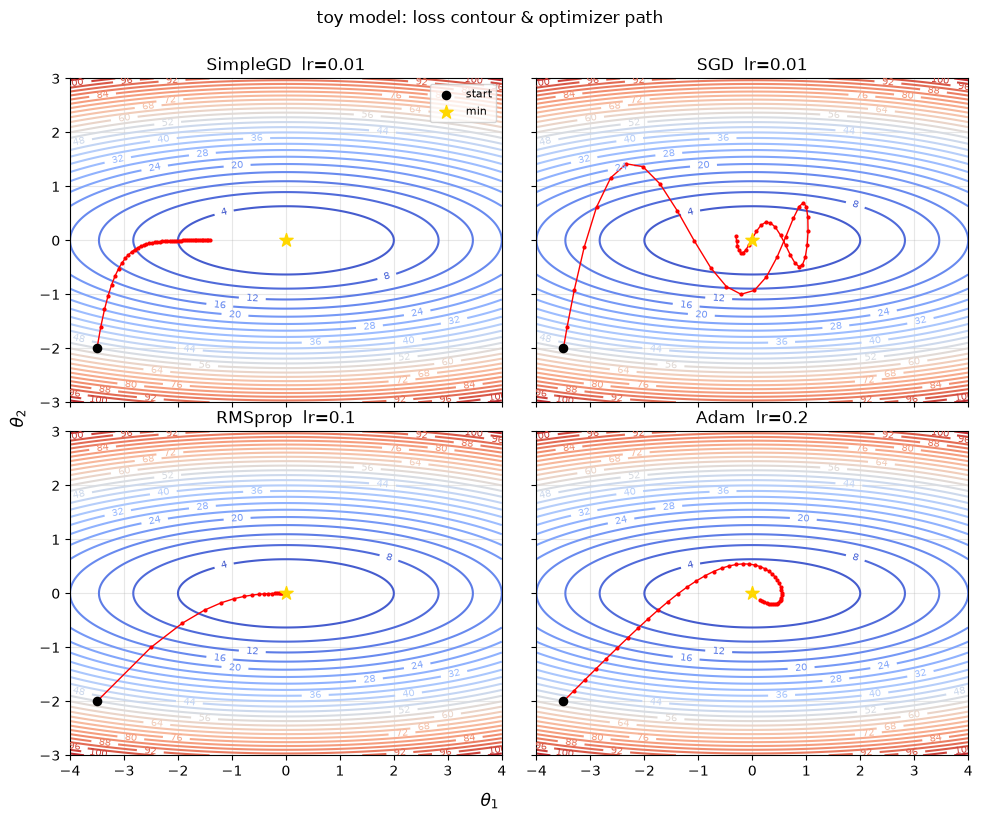

In [6]:
configs = [
    ("SimpleGD", 0.01),
    ("SGD", 0.01),
    ("RMSprop", 0.1),
    ("Adam", 0.2),
]

contours = plot_contours_subplots(configs, steps=45)

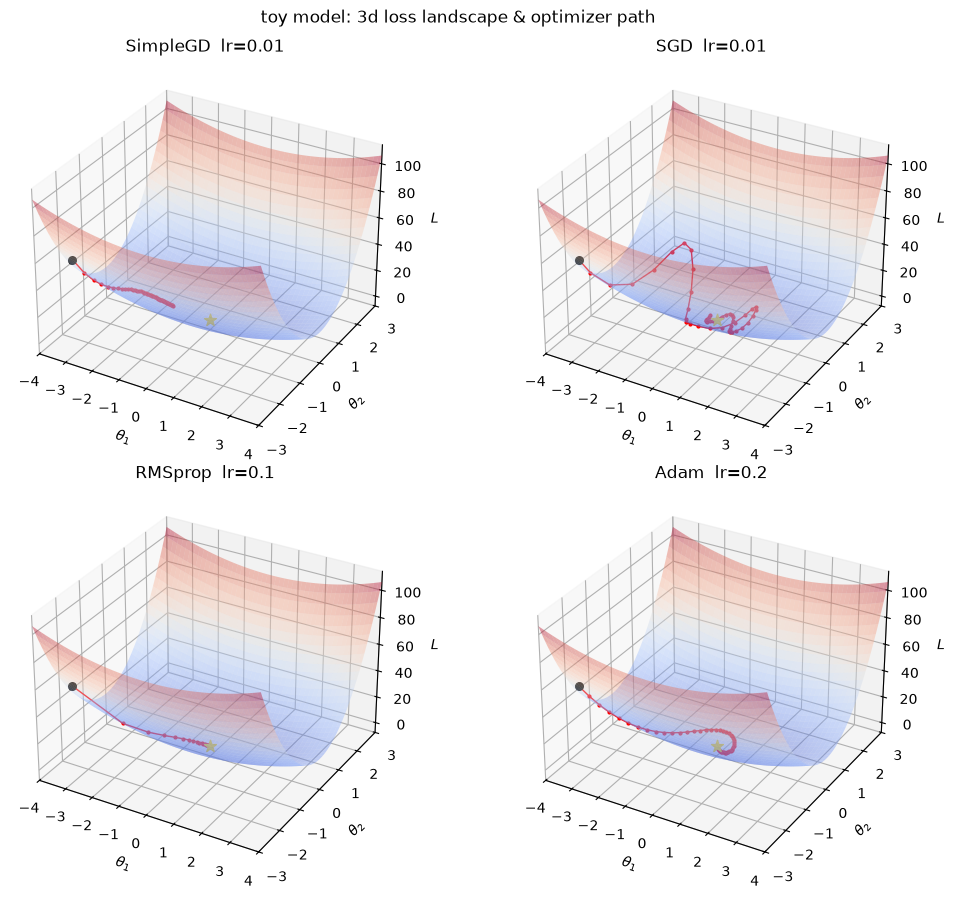

In [7]:
surface_3d = plot_surfaces_subplots(configs, steps=45)

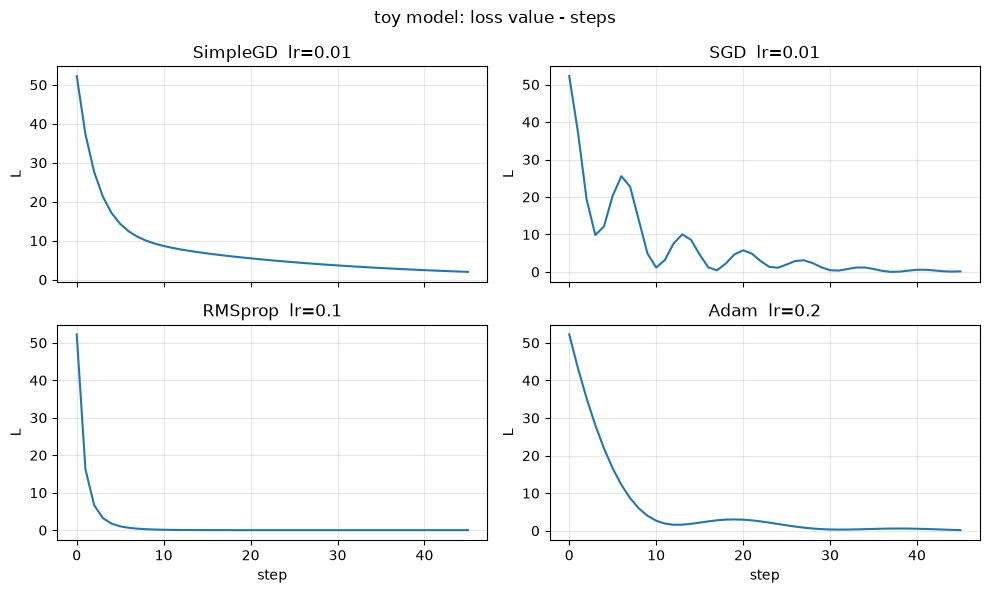

In [8]:
loss_steps = plot_loss_curves_subplots(configs, steps=45)

#### 3.2) What's special?

> $\eta$ stands for learning rate, $\mu$ stands for momentum.

On $L=\theta_1^2+10\theta_2^2$,

1. **Simple GD** works fine in this case, but it tends to take a more hesitant or zigzag path toward the origin for more cases, especially when we choose a higher learning rate. 
2. **Momentum** curves the trajectory and moves faster along the flat direction. But it's still gradient descent, zigzagging isn't completely fixed.
3. **RMSProp and Adam** adapt the step
along each axis, so they usually approach the minimum with less drama
once $\eta$ is in a reasonable range. 

But the ranking of paths still depends on the learning rate: (the visualization demonstrates well 🤔)

> **A “better” optimizer with a bad $\eta$ can look worse than simple GD with a good $\eta$.**

**Trade-offs**

| Optimizer | Strengths | Weaknesses |
|-----------|-----------|------------|
| SimpleGD | Simple; easy to interpret | Slow in narrow valleys; one global $\eta$ |
| SGD + Momentum | Accelerates along steady directions | Can overshoot; $\eta$ and $\mu$ both matter |
| RMSProp | Per-coordinate adaptive steps | Still needs a sensible $\eta$ |
| Adam | Strong default; fast early progress | Not always the best final generalization in vision; $\eta$ still matters |

The toy problem is noise-free and only two-dimensional. CIFAR-10 training
adds mini-batch noise and many more parameters, so in the next subsection, 
we're checking these behavior on a real CIFAR-10 model.


#### 3.3) Hello, my model!

In [9]:
torch.manual_seed(0)
X_train, y_train, X_test, y_test = load_cifar10_official()
loss_fn = CrossEntropyLoss()
loader = DataLoaderLite(X_train, y_train, batch_size=128, shuffle=True)

def make_model():
    m = Sequential([Linear(3072, 256), ReLU(), Linear(256, 10)])
    with torch.no_grad():
        m.layers[-1].weight *= 0.1
        if m.layers[-1].bias is not None:
            m.layers[-1].bias.zero_()
    return m

runs = {}
specs = [
    ("SimpleGD",  lambda p: SimpleGD(p, lr=1e-2)),
    ("Momentum",  lambda p: SGD(p, lr=1e-2, momentum=0.9)),
    ("RMSprop",   lambda p: RMSprop(p, lr=1e-3)),
    ("Adam",      lambda p: Adam(p, lr=3e-4)),
]

for name, opt_fn in specs:
    torch.manual_seed(0)
    model = make_model()
    opt = opt_fn(model.parameters())
    runs[name] = {"model": model, "opt": opt, "history": []}

for epoch in range(5):
    for xb, yb in loader:
        for name, r in runs.items():
            loss = train_step(r["model"], loss_fn, r["opt"], xb, yb)
            r["history"].append(loss)
    msg = ", ".join(f"{n}={runs[n]['history'][-1]:.4f}" for n in runs)
    print(f"epoch {epoch+1}: {msg}")

print("---summary---")

for name, r in runs.items():
    print(f"{name: <8} train {accuracy(r["model"], X_train, y_train): .4f} test {accuracy(r["model"], X_test, y_test): .4f}")

epoch 1: SimpleGD=1.8160, Momentum=1.4435, RMSprop=1.5402, Adam=1.4943
epoch 2: SimpleGD=1.6655, Momentum=1.4326, RMSprop=1.7042, Adam=1.4857
epoch 3: SimpleGD=1.6337, Momentum=1.4721, RMSprop=1.4584, Adam=1.4387
epoch 4: SimpleGD=1.4696, Momentum=1.3434, RMSprop=1.3590, Adam=1.2351
epoch 5: SimpleGD=1.5343, Momentum=1.3508, RMSprop=1.4916, Adam=1.2821
---summary---
SimpleGD train  0.4861 test  0.4733
Momentum train  0.5800 test  0.4875
RMSprop  train  0.5778 test  0.4958
Adam     train  0.5958 test  0.5187


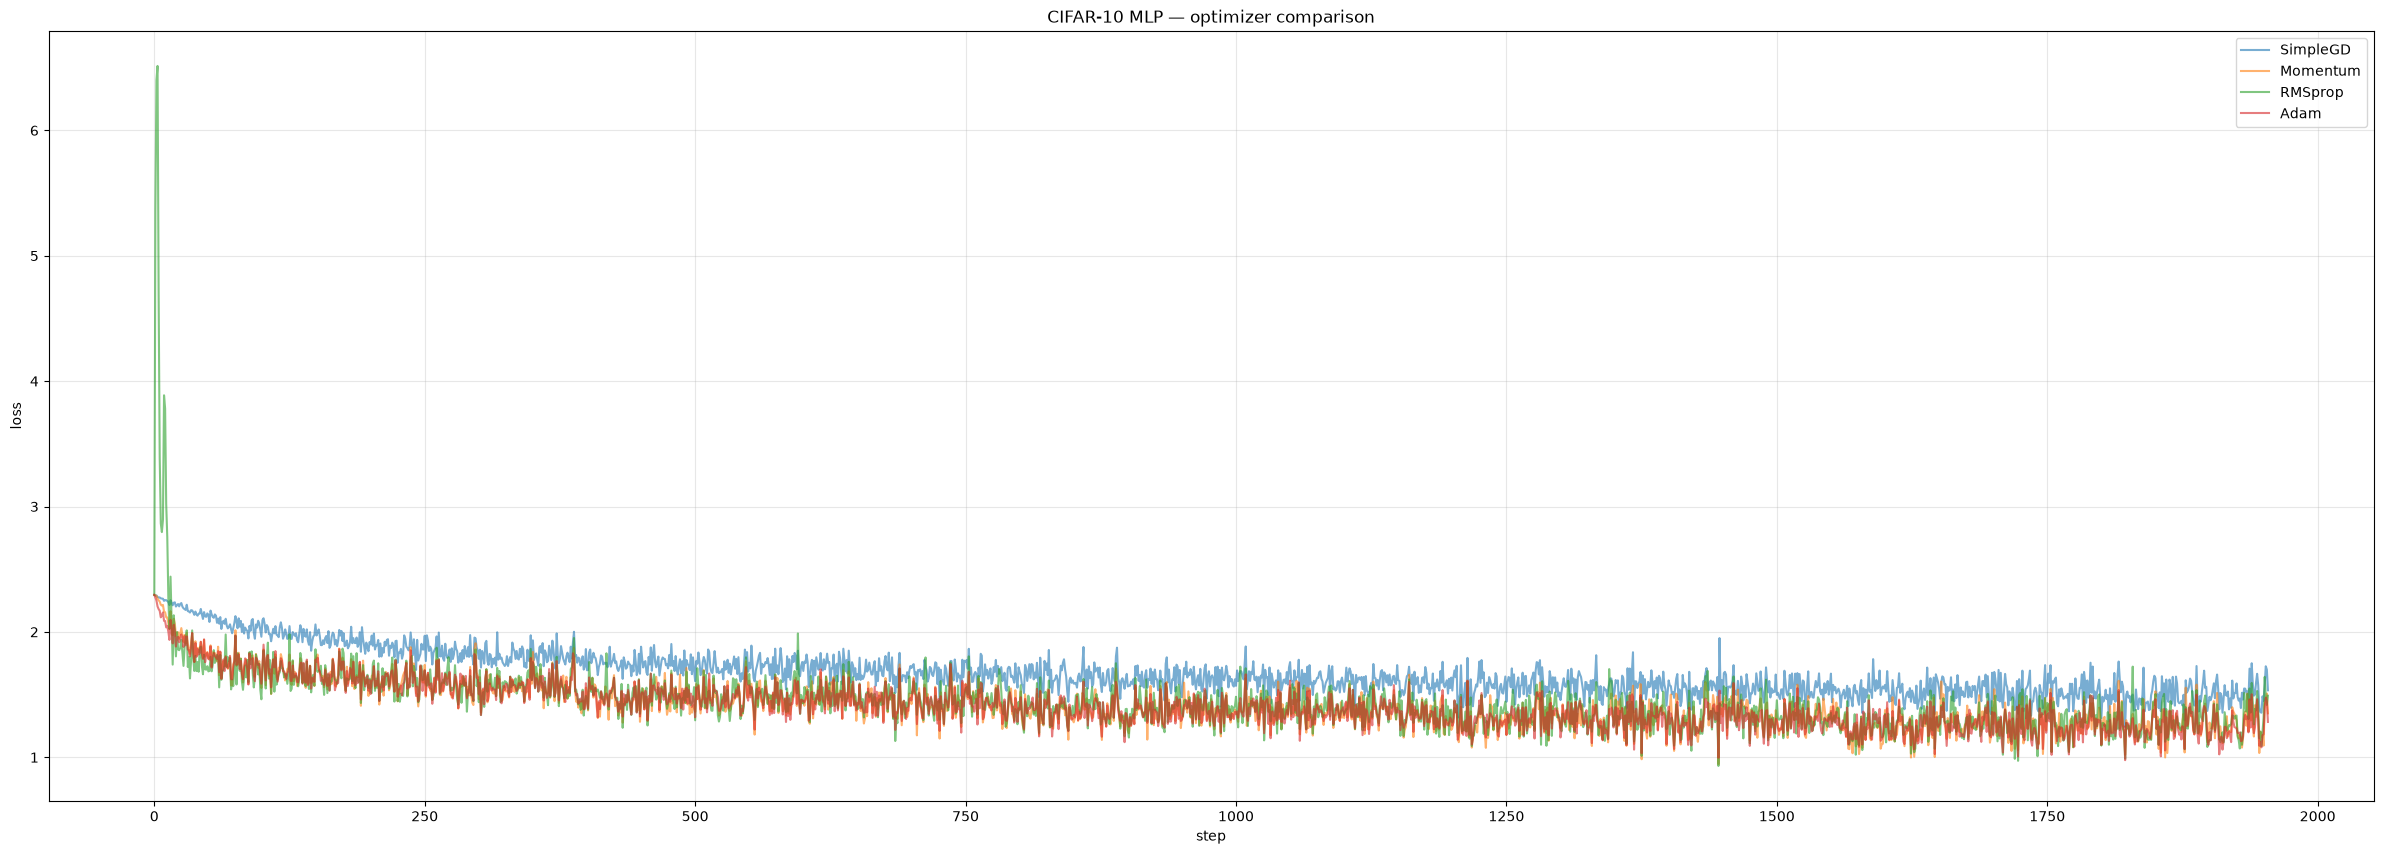

In [10]:
plt.figure(figsize=(30, 10))
for name, r in runs.items():
    plt.plot(r['history'], label=name, alpha=0.6)
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.title("CIFAR-10 MLP — optimizer comparison")
plt.grid(alpha=0.3)
plt.show()

### 4) Initializations

The optimizer comparison assumes a usable forward scale. Section 4 looks at initialization: without proper weight scaling, pre-activations can collapse or explode, and then optimizer curves become hard to interpret.

Okay, so far our first model works well, but something really detail hides in the net silently. you can find it out from the visualization below.

#### 4.1) Pre-activations & Visualizations

ReLU is our non-linearity; its gradient is simple:

$$\mathrm{ReLU}(x)=\begin{cases}x & x>0 \\ 0 & x\leqslant 0\end{cases},
\quad
\frac{\partial\mathrm{ReLU}}{\partial x}=\begin{cases}1 & x>0 \\ 0 & x\leqslant 0\end{cases}$$

> NOTE: $z$ is pre-activation, the output of Linearity, before ReLU.

In short, 

1. **The distribution shrinks**, after layers, $z$ piles up near zero.
2. **The input of deeper layers are weak**, deeper layers only see a very weak $h$, so unless weights are huge (usually unstable), the signal stays weak.
3. **Neurons learn slowly**, the weight gradients scale with activations, neurons learn slower with small gradients.

And here's why:

Without a proper weight scaling, the standard deviation of pre-activations often shrinks layer by layer in a deeper net, so $z$ piles up near zero.

In the forward pass, small pre-activations become small activations $h=\mathrm{ReLU}(z)$, so deeper layers receive a very weak signal and contribute little effective computation.

In the backward pass, ReLU’s local slope is only $0$ or $1$, but weight gradients still scale with the forward activations $h$ (`dW = h.T @ dz`). When $h$ is tiny, parameter updates become tiny as well; units with $z\leqslant 0$ also get zero ReLU gradient. Stacking many such layers makes learning very slow.

For saturating non-linearities such as $\tanh$, a *different* failure mode is also important: if pre-activations become *too large*, $\tanh'(z)\to 0$ and gradients vanish in the saturated regime. Collapse toward zero and explosion into saturation are both symptoms of bad scale, not the same mechanism. To know more about visualizing initializations and language model, this is [my blog post](https://telingc.github.io/2026/08/19/noob-neural-nets/).

too small gain (collapse)                | L1 mean=-0.0003 std=1.9585e-01
too small gain (collapse)                | L2 mean=-0.0008 std=2.6979e-02
too small gain (collapse)                | L3 mean=-0.0001 std=3.5351e-03
gain=1, no ReLU √2 (mild drift)          | L1 mean=-0.0142 std=9.8863e-01
gain=1, no ReLU √2 (mild drift)          | L2 mean=-0.0214 std=6.8700e-01
gain=1, no ReLU √2 (mild drift)          | L3 mean=+0.0296 std=4.8427e-01
too large gain (explosion)               | L1 mean=-0.0008 std=2.1002e+00
too large gain (explosion)               | L2 mean=-0.0053 std=2.2762e+00
too large gain (explosion)               | L3 mean=-0.0061 std=2.3235e+00
Kaiming gain=√2 (stable)                 | L1 mean=-0.0171 std=1.3398e+00
Kaiming gain=√2 (stable)                 | L2 mean=-0.0379 std=1.3372e+00
Kaiming gain=√2 (stable)                 | L3 mean=+0.0356 std=1.2916e+00


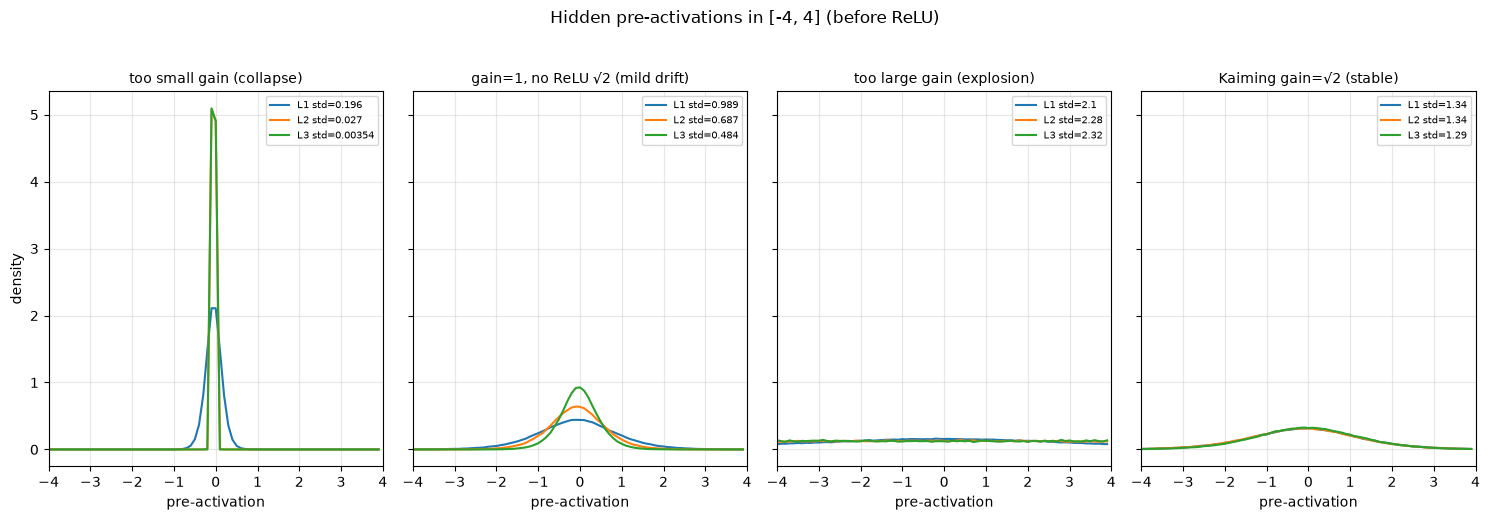

In [11]:
fig = plot_preact_four_gains(X_train[:1024], n_hidden_layers=3, xlim=(-4, 4), figsize = (15, 5))
plt.show()

#### 4.2) Initializations
The problem revealed from the graph above is about **how to keep standard deviation stable?**.

We can scale weights by a factor that depends on fan-in and a gain for the non-linearity (e.g. $\sqrt{2}$ for ReLU).

- **It shrinks**, if the factor is too small.
- **It expands**, if the factor is too large.

Kaiming He's team figured out a way to deal with the problem, that was called [*Kaiming Init*](https://arxiv.org/abs/1502.01852) or *He init*.

Now I'm skipping the mathematics and write the result of the Kaiming Init paper:

**Kaiming / He (normal):**

$$
W \sim \mathcal{N}(0,\ \sigma^2),
\quad
\sigma = \frac{\mathrm{gain}}{\sqrt{\mathrm{fan}}}
$$

| Nonlinearity | Gain |
|--------------|------|
| linear / identity | $1$ |
| sigmoid | $1$ |
| tanh | $\frac{5}{3}$ |
| ReLU | $\sqrt{2}$ |
| Leaky ReLU (negative slope $a$) | $\sqrt{2/(1+a^2)}$ |
| SELU | $\frac{3}{4}$ |

For ReLU with $\mathrm{fan}=\mathrm{fan_in}$ and $\mathrm{gain}=\sqrt{2}$:

$$
\sigma = \sqrt{\frac{2}{\mathrm{fan\_in}}}
$$

In [12]:
def kaiming_uniform_(w, nonlinearity="relu"):
    fan_in = w.shape[0]
    gain = math.sqrt(2.0) if nonlinearity == "relu" else 1.0
    bound = math.sqrt(3.0) * gain / math.sqrt(fan_in)
    return w.uniform_(-bound, bound)

#### 4.3) Gaussian & Xavier

Before Kaiming, Fixed Gaussian scale or **Xavier Init**
initialization (especially with $\tanh$) are common choices.

1. **Gaussian**  

$$
W \sim \mathcal{N}(0,\ \sigma^2)
$$

**It's just fix the distribution. It works, but less flexible.**

with a hand-chosen $\sigma$ (e.g. $0.01$). It doesn't depend on
$\mathrm{fan_in}$ / $\mathrm{fan_out}$, so depth or width changes can
make the scale too small or too large.

2. **Xavier**

Keep variance stable for symmetric activations.

$$
W \sim \mathcal{N}\!\left(0,\ \frac{2}{n_{\mathrm{in}}+n_{\mathrm{out}}}\right)
\quad\text{or}\quad
W \sim U\!\left(-\sqrt{\frac{6}{n_{\mathrm{in}}+n_{\mathrm{out}}}},\
\sqrt{\frac{6}{n_{\mathrm{in}}+n_{\mathrm{out}}}}\right)
$$

Xavier is a strong default for $\tanh$-like units. For ReLU, Kaiming
(with $\mathrm{gain}=\sqrt{2}$) is usually more appropriate.

In [13]:
def gaussian_(w, std=0.01):
    return w.normal_(0.0, std)

def xavier_uniform_(w, gain=1.0):
    fan_in, fan_out = w.shape
    bound = gain * math.sqrt(6.0 / (fan_in + fan_out))
    return w.uniform_(-bound, bound)

#### 4.4) Putting it together

With pre-activation scales under control, training becomes a fairer test of
optimizers and learning-rate choices: the network is less likely to fail
only because the signal vanished or exploded at initialization.

In [14]:
model = Sequential([
    Linear(3072, 256),
    ReLU(),
    Linear(256, 256),
    ReLU(),
    Linear(256, 10),
])

def init_model(model, method="kaiming"):
    for layer in model.layers:
        if not isinstance(layer, Linear):
            continue
        if method == "kaiming":
            kaiming_uniform_(layer.weight, nonlinearity = "relu")
        elif method == "xavier":
            xavier_uniform_(layer.weight)
        elif method == "gaussian":
            gaussian_(layer.weight, std=0.01)
        else:
            raise ValueError(method)
        if layer.bias is not None:
            layer.bias.zero_()

init_model(model, method="kaiming")

with torch.no_grad():
    model.layers[-1].weight *= 0.1

In [15]:
X_train, y_train, X_test, y_test = load_cifar10_official()
loss_fn = CrossEntropyLoss()
opt = Adam(model.parameters(), lr = 3e-4)

loader = DataLoaderLite(X_train, y_train, batch_size = 128, shuffle=True)

loss_history = []
for epoch in range(5):
    for xb, yb in loader:
        loss = train_step(model, loss_fn, opt, xb, yb)
        loss_history.append(loss)
    print(f"epoch {epoch+1}, last loss {loss:.4f}")

print("train acc", accuracy(model, X_train, y_train))
print("test  acc", accuracy(model, X_test,  y_test))

epoch 1, last loss 1.3385
epoch 2, last loss 1.4784
epoch 3, last loss 1.3524
epoch 4, last loss 1.1349
epoch 5, last loss 1.1832
train acc 0.63192
test  acc 0.5379


### 5) Normalizations

![pencil](images/BalancingPencilChallenge.png "Figure 3: Balancing a pencil.")

So far, training a neural net can be tricky and parameters seems fragile. Tuning and understanding is much like balancing a pencil, a pure torture. 😫

And now we're introducing normalizations, a way to make the net less sensitive.

#### 5.1) BatchNorm

Precisely tuned, fragile initializations matter less today thanks to some modern innovations — one of which is batch normalization. So if you want a standard Gaussian for initialization, why not just *make* it Gaussian?

Statistically, scaling up by a factor of $n$ enlarges the standard deviation by $n$. 

So,

- if you need to center the distribution at zero, just subtract the mean of the pre-activations; 
- if you want unit variance, just divide by the standard deviation. 

And most importantly, all of this is built into the neural net — meaning we can ensure a roughly standard-normal pre-activation every iteration, firing the non-linearity at full capacity, and even giving the net extra parameter knobs to tune for a better fit.

Let's take a close look at these formulas, because they're simple and useful. For multi-layer nets it makes training more forgiving.

1. $\text{the mean of the pre-activations}$

$$\frac{1}{m}\sum_{i=1}^{m}x_i = \mu_{\mathcal{B}}$$

2. $\text{the variance of the pre-activations}$

$$\frac{1}{m-1}\sum_{i=1}^{m}(x_i-\mu_{\mathcal{B}})^2 = \sigma_{\mathcal{B}}^2$$

3. $\text{normalization}$

$$\frac{x_i-\mu_{\mathcal{B}}}{\sqrt{\sigma_{\mathcal{B}}^2+\epsilon}} = \hat{x_i}$$

4. $\text{scale and shift}$

$$\gamma\hat{x_i}+\beta = y_i \equiv \mathrm{BN}_{\gamma,\beta}(x_i)$$

For more details, here's [Andrej Karpathy](https://www.youtube.com/playlist?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ).

In [16]:
class BatchNorm1d:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        self.gamma.grad = None
        self.beta.grad = None
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            mean = x.mean(0)
            var = x.var(0, unbiased=False)
            with torch.no_grad():
                self.running_mean = (
                    1 - self.momentum
                ) * self.running_mean + self.momentum * mean
                self.running_var = (
                    1 - self.momentum
                ) * self.running_var + self.momentum * var
        else:
            mean = self.running_mean
            var = self.running_var

        xhat = (x - mean) / torch.sqrt(var + self.eps)
        self.out = self.gamma * xhat + self.beta
        self._cache = (x, xhat, mean, var)
        return self.out

    def backward(self, dout):
        x, xhat, mean, var = self._cache
        N = x.shape[0]
        dgamma = (dout * xhat).sum(0)
        dbeta = dout.sum(0)
        self.gamma.grad = dgamma if self.gamma.grad is None else self.gamma.grad + dgamma
        self.beta.grad = dbeta if self.beta.grad is None else self.beta.grad + dbeta

        dxhat = dout * self.gamma
        inv_std = 1.0 / torch.sqrt(var + self.eps)
        dx = (1.0 / N) * inv_std * (
            N * dxhat - dxhat.sum(0) - xhat * (dxhat * xhat).sum(0)
        )
        return dx

    def parameters(self):
        return [self.gamma, self.beta]

#### 5.2) LayerNorm

> NOTE: This part will be covered later.

In [17]:
class LayerNorm:
    def __init__(self, dim, eps=1e-5):
        self.eps = eps
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        self.gamma.grad = None
        self.beta.grad = None

    def __call__(self, x):
        mean = x.mean(-1, keepdim=True)
        var = x.var(-1, keepdim=True, unbiased=False)
        xhat = (x - mean) / torch.sqrt(var + self.eps)
        self.out = self.gamma * xhat + self.beta
        self._cache = (x, xhat, mean, var)
        return self.out

    def backward(self, dout):
        x, xhat, mean, var = self._cache
        dgamma = (dout * xhat).sum(0)
        dbeta = dout.sum(0)
        self.gamma.grad = dgamma if self.gamma.grad is None else self.gamma.grad + dgamma
        self.beta.grad = dbeta if self.beta.grad is None else self.beta.grad + dbeta

        dxhat = dout * self.gamma
        inv_std = 1.0 / torch.sqrt(var + self.eps)
        dx = inv_std * (
            dxhat
            - dxhat.mean(-1, keepdim=True)
            - xhat * (dxhat * xhat).mean(-1, keepdim=True)
        )
        return dx

    def parameters(self):
        return [self.gamma, self.beta]

### 6) Hyperparameters

Hyperparameters, you can imagine them a bunch of knobs you can play with.

And these two params are unchangable.
- **FAN_IN**: The input is a $32\text{px}\times32\text{px}$ picture with $3$ channels: RGB, so `FAN_IN` can and only be $32\times32\times3=3072$.
- **FAN_OUT**: We're classifing pictures into 10 classes, so the `FAN_OUT` can and only be $10$.

Here's what we can use to optimize the net:

1. `learning_rate`, learning rate.

2. `n_epoch`, how many times (steps / epoches) the net will be trained.

3. `n_layers`, the depth of the net.

4. `n_hidd`, the dimension of the hidden layer.

5. `batch_size`, the size of mini-batches.

#### 6.1) Some Experiments on Hyperparameters

So the idea is simple, keep other parameters fixed and tune one parameter per experiment.
From the table drawn below, increasing the scale of the hidden layer is a promising choice.

We achieved $\approx54\text{ percent}$ accuracy on the validation set, and the loss value came to $\approx 1$. But note that the accuracy gap between val and train is the highest among the experiments, our model may be over-fitting the dataset.

---layers---
[1/5] n_layers=0 n_hidd=256 batch_size=128 lr=0.0003
    -> val 0.4984  train 0.5892  loss 1.2751  (3.3s)
[2/5] n_layers=1 n_hidd=256 batch_size=128 lr=0.0003
    -> val 0.5232  train 0.6338  loss 1.1638  (5.4s)
[3/5] n_layers=2 n_hidd=256 batch_size=128 lr=0.0003
    -> val 0.5170  train 0.6494  loss 1.1364  (6.2s)
[4/5] n_layers=4 n_hidd=256 batch_size=128 lr=0.0003
    -> val 0.5148  train 0.6627  loss 1.1302  (9.8s)
[5/5] n_layers=8 n_hidd=256 batch_size=128 lr=0.0003
    -> val 0.4992  train 0.6440  loss 1.2100  (16.6s)
---hidd---
[1/4] n_layers=2 n_hidd=16 batch_size=128 lr=0.0003
    -> val 0.4114  train 0.4344  loss 1.6178  (2.4s)
[2/4] n_layers=2 n_hidd=64 batch_size=128 lr=0.0003
    -> val 0.4820  train 0.5545  loss 1.3471  (3.6s)
[3/4] n_layers=2 n_hidd=256 batch_size=128 lr=0.0003
    -> val 0.5170  train 0.6494  loss 1.1364  (7.5s)
[4/4] n_layers=2 n_hidd=1024 batch_size=128 lr=0.0003
    -> val 0.5360  train 0.7171  loss 1.0011  (32.7s)
---batch---
[1/5] n_l

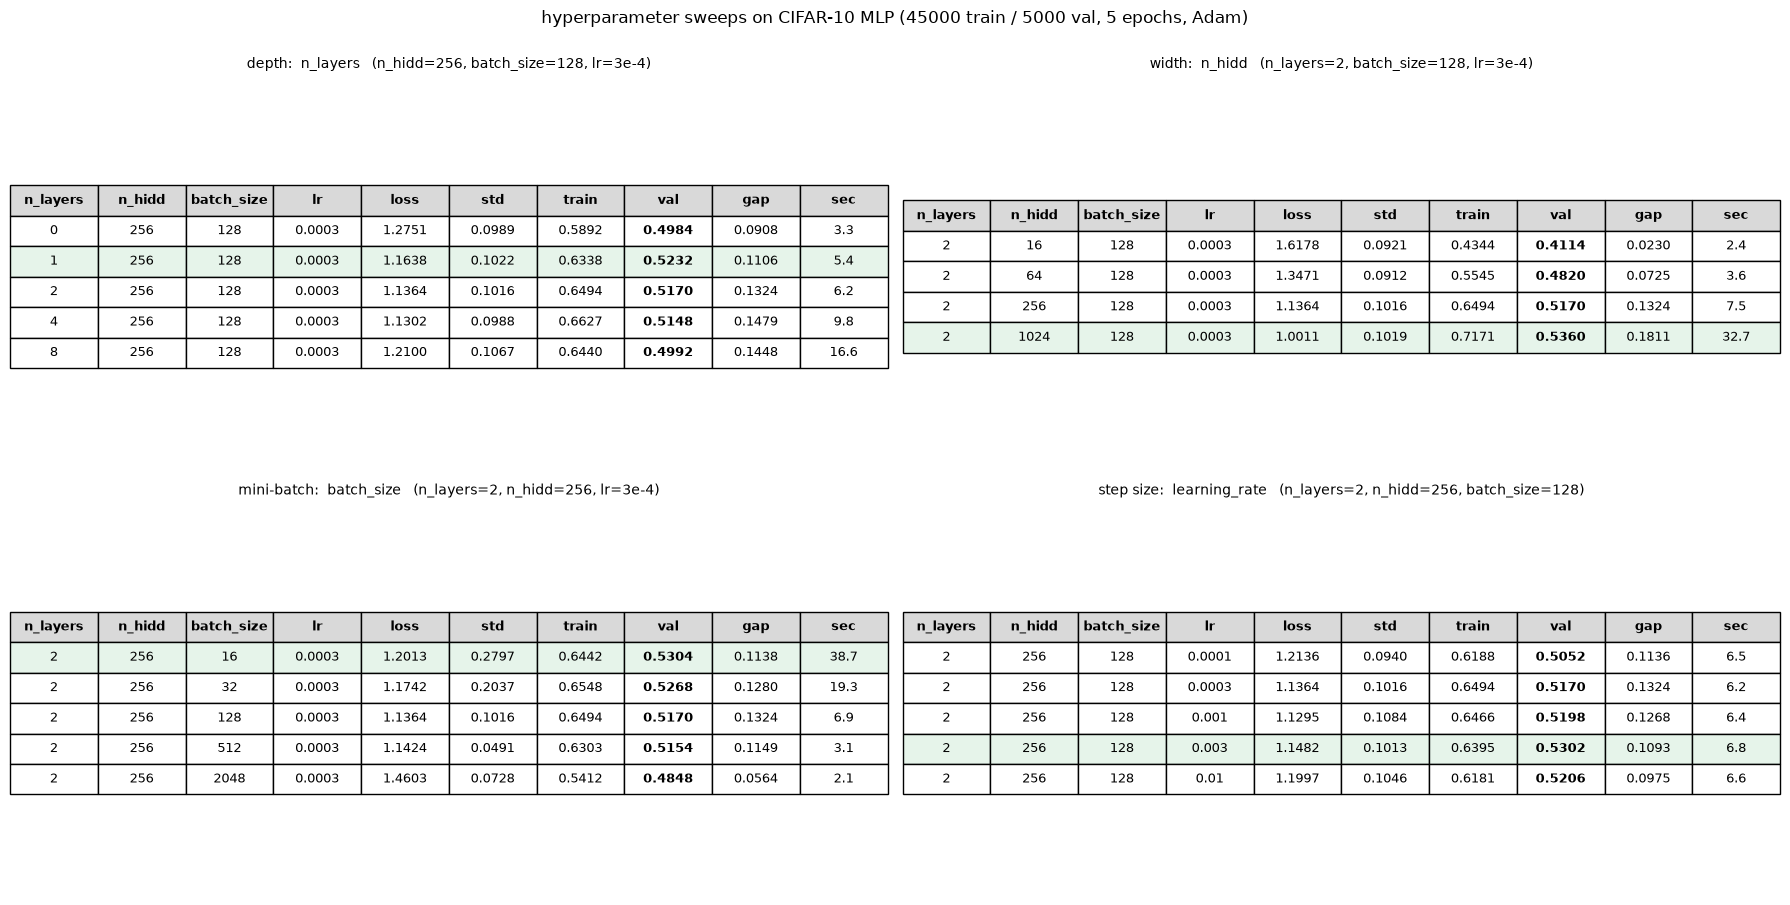

In [18]:
if "X_train" not in globals():
    X_train, y_train, X_test, y_test = load_cifar10_official()

FAN_IN, FAN_OUT = 3072, 10
N_TRAIN, N_VAL = 45000, 5000
N_EPOCH = 5

_split_g = torch.Generator().manual_seed(0)
_perm = torch.randperm(len(X_train), generator=_split_g)

JOBS = {
    "layers": [(d, 256, 128, 3e-4) for d in (0, 1, 2, 4, 8)],
    "hidd":   [(2, h, 128, 3e-4) for h in (16, 64, 256, 1024)],
    "batch":  [(2, 256, b, 3e-4) for b in (16, 32, 128, 512, 2048)],
    "lr":     [(2, 256, 128, lr) for lr in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2)],
}

LABELS = {
    "layers": "depth:  n_layers   (n_hidd=256, batch_size=128, lr=3e-4)",
    "hidd":   "width:  n_hidd   (n_layers=2, batch_size=128, lr=3e-4)",
    "batch":  "mini-batch:  batch_size   (n_layers=2, n_hidd=256, lr=3e-4)",
    "lr":     "step size:  learning_rate   (n_layers=2, n_hidd=256, batch_size=128)",
}

Xtr, ytr = X_train[_perm[:N_TRAIN]], y_train[_perm[:N_TRAIN]]
Xva, yva = X_train[_perm[N_TRAIN:N_TRAIN + N_VAL]], y_train[_perm[N_TRAIN:N_TRAIN + N_VAL]]

def build_model(n_layers, n_hidd, fan_in=FAN_IN, fan_out=FAN_OUT):
    model = Sequential(
        [Linear(fan_in, n_hidd), ReLU()]
        + [
            layer
            for _ in range(n_layers)
            for layer in (
                Linear(n_hidd, n_hidd, bias=False),
                BatchNorm1d(n_hidd),
                ReLU(),
            )
        ]
        + [Linear(n_hidd, fan_out)]
    )
    with torch.no_grad():
        model.layers[-1].weight *= 0.1
        if model.layers[-1].bias is not None:
            model.layers[-1].bias.zero_()
    return model


def run_config(n_layers, n_hidd, batch_size, lr, n_epoch, verbose=False):
    torch.manual_seed(0)
    model = build_model(n_layers, n_hidd)
    loss_fn = CrossEntropyLoss()
    opt = Adam(model.parameters(), lr=lr)
    loader = DataLoaderLite(Xtr, ytr, batch_size=batch_size, shuffle=True)

    history, t0 = [], time.time()
    for epoch in range(n_epoch):
        for xb, yb in loader:
            history.append(train_step(model, loss_fn, opt, xb, yb))
        if verbose:
            print(f"    epoch {epoch + 1}/{n_epoch}  loss {np.mean(history[-50:]):.4f}")

    return {
        "n_layers": n_layers,
        "n_hidd": n_hidd,
        "batch_size": batch_size,
        "lr": lr,
        "n_epoch": n_epoch,
        "loss_first": history[0],
        "loss_last50": float(np.mean(history[-50:])),
        "loss_std50": float(np.std(history[-50:])),
        "train_acc": accuracy(model, Xtr, ytr),
        "val_acc": accuracy(model, Xva, yva),
        "seconds": time.time() - t0,
        "history": history,
    }


def sweep(jobs, n_epoch=N_EPOCH, verbose=False):
    results = []
    for i, (n_layers, n_hidd, batch_size, lr) in enumerate(jobs, 1):
        print(f"[{i}/{len(jobs)}] n_layers={n_layers} n_hidd={n_hidd} "
              f"batch_size={batch_size} lr={lr}", flush=True)
        r = run_config(n_layers, n_hidd, batch_size, lr, n_epoch, verbose=verbose)
        print(f"    -> val {r['val_acc']:.4f}  train {r['train_acc']:.4f}  "
              f"loss {r['loss_last50']:.4f}  ({r['seconds']:.1f}s)")
        results.append(r)
    return results

results_all = {}
for name, jobs in JOBS.items():
    print(f"---{name}---")
    results_all[name] = sweep(jobs, n_epoch=N_EPOCH, verbose=False)

ncols = 2
nrows = -(-len(JOBS) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(9 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, name in zip(axes, JOBS):
    plot_table(results_all[name], ax, LABELS[name])
for ax in axes[len(JOBS):]:
    ax.axis("off")
fig.suptitle(f"hyperparameter sweeps on CIFAR-10 MLP "
             f"({N_TRAIN} train / {N_VAL} val, {N_EPOCH} epochs, Adam)", y=1.0)
fig.tight_layout()
plt.show()

#### 6.2) Visualizations

So far we've done quite a lot visualizations, it's a good choice to draw a graph and visualise it. Let's take initializations for example, improper initializations are dragging the overall performance silently, it's quite tricky to debug. But visualizing the pre-activations of each layer gives an intuitive understanding.

But experimenting with different hyperparameters is the best way still. We can summarize some empirical conclusions next section.

#### 6.3) Some Empirical Methods

Before changing anything, here are two signals:

- **loss curve** → is optimization working?
- **train / val gap** → is capacity fitting or overfitting?

**Turn one knob at a time**. Fix the curve first (`learning_rate`, `batch_size`), then capacity (`n_hidd`, `n_layers`), then train longer (`n_epoch`).

1. **learning_rate**

If the loss falls very slowly (almost a straight line), try a larger lr.
If the loss is violent, jumps up, or becomes `nan`, use a smaller lr.
A shaky curve is not only about lr: small `batch_size` also adds noise, so check both.
With Adam, a wide lr range can look similar on accuracy; still watch the loss — too large an lr often makes the final loss rise again.

2. **n_epoch**

Train while validation accuracy improves. If train accuracy keeps rising but val flattens or drops, you are starting to overfit — stop, regularize, or get more data; more epochs alone will usually widen the gap.
Use a real validation split for this decision; do not tune on the test set.

3. **n_layers**

Depth adds capacity, but it saturates fast on this MLP.
If both train and val are low and close (underfit), add a block.
If val stops improving while train still climbs, extra depth mostly memorizes and costs more time.
A deeper net that “does not learn” is often a scale / init issue (Section 4), not “not enough layers.”

4. **n_hidd**

Usually the first capacity knob when the model underfits: wider hidden layers tend to raise both train and val accuracy.
When $\text{train}\geqslant\text{val}$, width is no longer the bottleneck — use regularization or more data, and prefer the **smallest** width where val saturates.

5. **batch_size**

**Small** batches → noisier loss, more updates per epoch, noise acts a bit like regularization.
**Large** batches → smoother loss, fewer updates per epoch; with fixed `n_epoch` the loss may fall slower unless lr is increased. Tune `batch_size` and `learning_rate` together.

### 7) Training

Now we can test and train a model.

In [19]:
torch.manual_seed(0)
FAN_IN = 3072
FAN_OUT = 10

n_layers = 1
n_epoch = 5
n_hidd = 1024
batch_size = 16
learning_rate = 3e-3

model = Sequential(
    [Linear(FAN_IN, n_hidd), ReLU()] +
    [layer for _ in range(n_layers) for layer in (
        Linear(n_hidd, n_hidd, bias = False), 
        BatchNorm1d(n_hidd), 
        ReLU())] +
    [Linear(n_hidd, FAN_OUT)])

with torch.no_grad():
    model.layers[-1].weight *= 0.1
    if model.layers[-1].bias is not None:
        model.layers[-1].bias.zero_()

In [20]:
X_train, y_train, X_test, y_test = load_cifar10_official()
loss_fn = CrossEntropyLoss()
opt = Adam(model.parameters(), lr = learning_rate)

loader = DataLoaderLite(X_train, y_train, batch_size = batch_size, shuffle=True)

loss_history = []
for epoch in range(n_epoch):
    for xb, yb in loader:
        loss = train_step(model, loss_fn, opt, xb, yb)
        loss_history.append(loss)
    print(f"epoch {epoch+1}, last loss {loss:.4f}")

epoch 1, last loss 1.7340
epoch 2, last loss 1.2211
epoch 3, last loss 1.2460
epoch 4, last loss 1.6345
epoch 5, last loss 1.0630


In [21]:
print("train acc", accuracy(model, X_train, y_train))
print("test  acc", accuracy(model, X_test,  y_test))
print("gap      ", abs(accuracy(model, X_train, y_train) - accuracy(model, X_test,  y_test)))

train acc 0.6466
test  acc 0.5397
gap       0.1069


### 8) Next Steps

Now you might wonder: **why this notebook is far more complex than the numpy version?**

In this version, our implementations are corresponding with the PyTorch API using. And we're using GPU for computation which is much faster than NumPy.

For next steps, we'll implement CNN. By then we could find that the CNN has higher accuracy ($\approx 80\text{ percent}$) and higher confidence in general, and that means CNN is more likely to make wrong predictions confidently.

Now, if you ever feel curious about the fancy GIF picture in the 0) Intro, code here provides you a real time version, 2 neural nets (MLP and CNN, CNN will be implement in future versions) run directly in this notebook **in real time**.

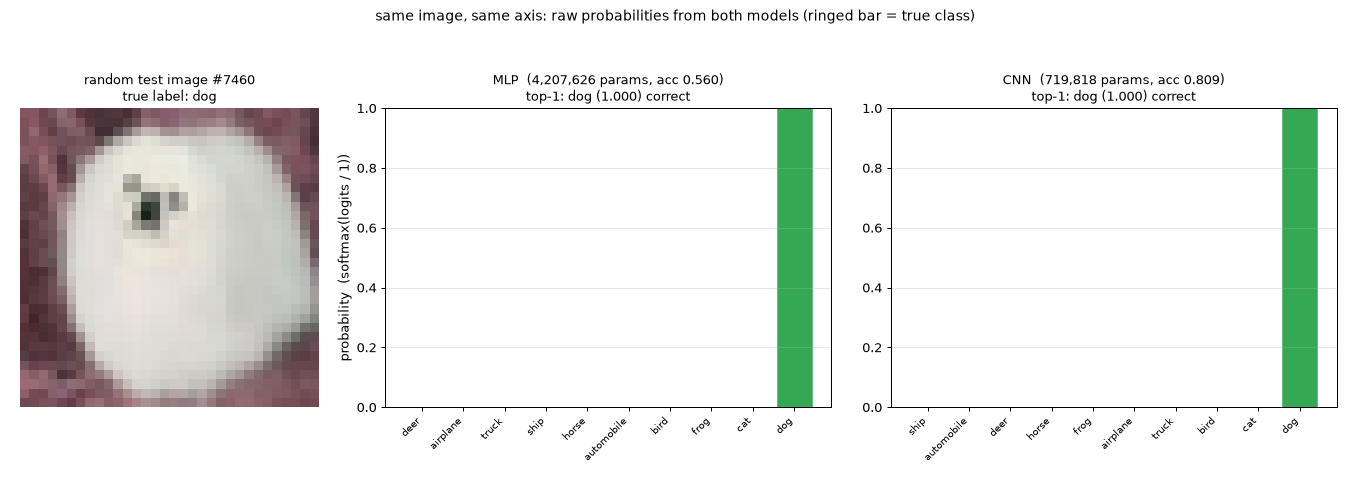

[1/10] image #2291  true=dog        | MLP top1=frog       ok=False bars>0.01=3 | CNN top1=dog        ok=True bars>0.01=1
[2/10] image #2823  true=cat        | MLP top1=deer       ok=False bars>0.01=4 | CNN top1=cat        ok=True bars>0.01=1
[3/10] image #7487  true=automobile | MLP top1=automobile ok=True bars>0.01=1 | CNN top1=automobile ok=True bars>0.01=1
[4/10] image #7423  true=frog       | MLP top1=frog       ok=True bars>0.01=1 | CNN top1=frog       ok=True bars>0.01=3
[5/10] image #7279  true=dog        | MLP top1=dog        ok=True bars>0.01=3 | CNN top1=dog        ok=True bars>0.01=1
[6/10] image #3762  true=automobile | MLP top1=automobile ok=True bars>0.01=3 | CNN top1=truck      ok=False bars>0.01=3
[7/10] image #4052  true=dog        | MLP top1=frog       ok=False bars>0.01=3 | CNN top1=dog        ok=True bars>0.01=2
[8/10] image #5860  true=airplane   | MLP top1=truck      ok=False bars>0.01=4 | CNN top1=airplane   ok=True bars>0.01=1
[9/10] image #9819  true=cat       

In [24]:
WEIGHTS = Path("weights")
if not WEIGHTS.exists():
    raise FileNotFoundError(f"weights folder not found: {WEIGHTS.resolve()}")
print("weights folder:", WEIGHTS.resolve())

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEMP = {"mlp": 1.0, "cnn": 1.0}
YMAX = 1.0
DATA_ROOT = "../assignment_1_1/datasets"
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

FRAME_MS    = 110
RISE_FRAMES = 24
HOLD_MS     = 2600
N_IMAGES = 10

MODELS = {}
for name in ("mlp", "cnn"):
    ck = torch.load(WEIGHTS / f"{name}.pt", map_location="cpu", weights_only=True)
    model = BUILDERS[ck["arch"]["kind"]](ck["arch"])
    model.load_state_dict(ck["state_dict"])
    MODELS[name] = {"model": model.eval().to(DEVICE),
                    "test_acc": ck["metrics"]["test_acc"],
                    "params": ck["metrics"]["n_params"]}
    print(f"{name}: {MODELS[name]['params']:,} params, test acc {MODELS[name]['test_acc']:.4f}")

test_set = datasets.CIFAR10(
    DATA_ROOT, train=False, download=False,
    transform=transforms.Compose([transforms.ToTensor(),
                                  transforms.Normalize(MEAN, STD)]),
)
CLASSES = test_set.classes
_std = torch.tensor(STD).view(3, 1, 1)
_mean = torch.tensor(MEAN).view(3, 1, 1)

rng = random.Random(None)
log = []

for k in range(N_IMAGES):
    fig, bars, heights, info = build_figure(idx=rng.randrange(len(test_set)))
    start = cascade_start(heights)

    for f in range(RISE_FRAMES + 1):
        t0 = time.time()
        bar_step(bars, heights, start + (1 - start) * f / RISE_FRAMES)

        clear_output(wait=True)
        display(Image(data=frame_png(fig, dpi=90)))

        wait = (FRAME_MS if f < RISE_FRAMES else HOLD_MS) / 1000
        dt = time.time() - t0
        if dt < wait:
            time.sleep(wait - dt)
    plt.close(fig)

    log.append(f"[{k+1}/{N_IMAGES}] image #{info['idx']}  "
               f"true={CLASSES[info['label']]:<10} "
               f"| MLP top1={info['mlp']['top1']:<10} ok={info['mlp']['correct']} "
               f"bars>0.01={info['mlp']['visible_bars']} "
               f"| CNN top1={info['cnn']['top1']:<10} ok={info['cnn']['correct']} "
               f"bars>0.01={info['cnn']['visible_bars']}")

print("\n".join(log))

### 9) Conclusion